# Discovering the 3-Point Line with Competitive Learning

Can a competitive learning network find the NBA 3-point line using only where shots were taken? This notebook trains one on shot locations from 2000-01 to 2024-25 and tracks how its map of the court changes as the league moved toward the 3.

**Contents**

1. Data: counts, train and test split, heatmaps, shot distance, zone shares
2. Experiments 1 and 2: Finding the line in 2000-01 and 2024-25
3. Experiment 3: Sequential training across eras
4. Experiment 4: Polar inputs and the shape of the line
5. Limitations and possible improvements

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/BiyonWann/bballNeuro.git"

if "google.colab" in sys.modules:
    subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir("bballNeuro")
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", "requirements.txt"], check=True)
else:
    print("Not running in Colab, setup skipped")

Not running in Colab, setup skipped


In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from threept import court, data

DATA_DIR = os.environ.get("BBALL_DATA_DIR", "data")
SEED = 0
N_TRAIN = 20000

## 1. Data

Shot-detail files come from the public GitHub repository `shufinskiy/nba_data`, which mirrors the NBA's official shot-chart data. Each row is one field-goal attempt. The model sees only `LOC_X` and `LOC_Y`. `SHOT_TYPE` and `SHOT_ZONE_BASIC` are used only for evaluation.

In [3]:
raw_shots = {}
cleaned_shots = {}
for season, start_year in data.SEASONS.items():
    raw_shots[season] = data.load_season(start_year, DATA_DIR)
    cleaned = data.clean_shots(raw_shots[season])
    cleaned_shots[season] = data.add_features(cleaned)

In [4]:
count_rows = []
for season, raw in raw_shots.items():
    missing = raw["LOC_X"].isna() | raw["LOC_Y"].isna()
    count_rows.append(
        {
            "season": season,
            "raw rows": len(raw),
            "games": raw["GAME_ID"].nunique(),
            "Backcourt rows": (raw["SHOT_ZONE_BASIC"] == "Backcourt").sum(),
            "missing coordinates": missing.sum(),
            "rows after cleaning": len(cleaned_shots[season]),
        }
    )
counts = pd.DataFrame(count_rows).set_index("season")
counts

,raw rows,games,Backcourt rows,missing coordinates,rows after cleaning
season,,,,,
2000-01,191662,1189,298,0,191364
2008-09,199030,1230,445,0,198585
2015-16,207893,1230,440,0,207453
2024-25,219527,1230,517,0,219010


### Train and test split

In [5]:
splits = {}
split_rows = []
for season, start_year in data.SEASONS.items():
    train, test = data.prepare_season(start_year, seed=SEED, n_train=N_TRAIN, data_dir=DATA_DIR)
    splits[season] = (train, test)
    shared_games = set(train["GAME_ID"]) & set(test["GAME_ID"])
    assert len(shared_games) == 0, f"{season}: games in both train and test"
    split_rows.append(
        {
            "season": season,
            "train rows": len(train),
            "test rows": len(test),
            "test games": test["GAME_ID"].nunique(),
            "shared games": len(shared_games),
        }
    )
pd.DataFrame(split_rows).set_index("season")

,train rows,test rows,test games,shared games
season,,,,
2000-01,20000,38292,238,0
2008-09,20000,39960,246,0
2015-16,20000,41735,246,0
2024-25,20000,44010,246,0


### Shot heatmaps

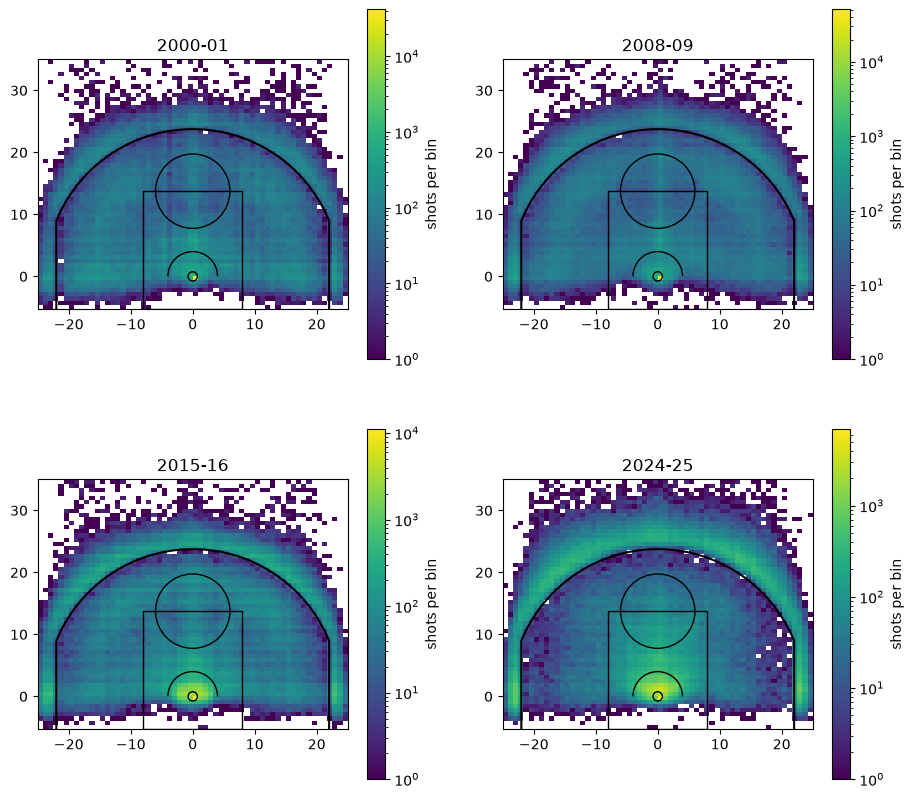

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, (season, shots) in zip(axes.flat, cleaned_shots.items()):
    court.plot_shot_heatmap(shots["x_ft"], shots["y_ft"], ax=ax)
    ax.set_title(season)
    fig.colorbar(ax.collections[0], ax=ax, label="shots per bin")
plt.show()

**Interpretation:** to be written